In [ ]:
# Module 6: Climate Change Scenario Analysis

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib

print("Climate Change Scenario Analysis")
print("--------------------------------")
print("Libraries loaded successfully!")

Climate Change Scenario Analysis
--------------------------------
Libraries loaded successfully!


In [ ]:
from google.colab import drive
import os

# Mount Google Drive
drive.mount("/content/drive")

print("\nSearching for yield-related files...\n")

for root, dirs, files in os.walk("/content/drive/MyDrive"):
    for file in files:
        if "yield" in file.lower():
            print(os.path.join(root, file))

Mounted at /content/drive

Searching for yield-related files...

/content/drive/MyDrive/crop_yield_prediction_model.pkl
/content/drive/MyDrive/Colab Notebooks/Crop Yield Prediction.ipynb


In [ ]:
import os

print("Searching for CSV/XLSX datasets...\n")

for root, dirs, files in os.walk("/content/drive/MyDrive"):
    for file in files:
        if file.lower().endswith((".csv", ".xlsx", ".xls")):
            print(os.path.join(root, file))

Searching for CSV/XLSX datasets...



In [ ]:
import pandas as pd

url = "https://raw.githubusercontent.com/Aswins10/Agricultural-Crop-Yield-in-Indian-States-Dataset/main/crop_yield.csv"

climate_df = pd.read_csv(url)

print("Dataset shape:", climate_df.shape)

print("\nColumns:")
print(climate_df.columns.tolist())

print("\nFirst 5 rows:")
display(climate_df.head())

Dataset shape: (19689, 10)

Columns:
['Crop', 'Crop_Year', 'Season', 'State', 'Area', 'Production', 'Annual_Rainfall', 'Fertilizer', 'Pesticide', 'Yield']

First 5 rows:


,Crop,Crop_Year,Season,State,Area,Production,Annual_Rainfall,Fertilizer,Pesticide,Yield
0,Arecanut,1997,Whole Year,Assam,73814.0,56708,2051.4,7024878.38,22882.34,0.796087
1,Arhar/Tur,1997,Kharif,Assam,6637.0,4685,2051.4,631643.29,2057.47,0.710435
2,Castor seed,1997,Kharif,Assam,796.0,22,2051.4,75755.32,246.76,0.238333
3,Coconut,1997,Whole Year,Assam,19656.0,126905000,2051.4,1870661.52,6093.36,5238.051739
4,Cotton(lint),1997,Kharif,Assam,1739.0,794,2051.4,165500.63,539.09,0.420909


In [ ]:
# Clean climate/yield dataset

climate_df = climate_df.copy()

# Convert numerical columns
numeric_cols = [
    "Crop_Year",
    "Area",
    "Production",
    "Annual_Rainfall",
    "Fertilizer",
    "Pesticide",
    "Yield"
]

for col in numeric_cols:
    climate_df[col] = pd.to_numeric(
        climate_df[col],
        errors="coerce"
    )

# Remove missing values
climate_df = climate_df.dropna(
    subset=[
        "Crop",
        "Crop_Year",
        "Season",
        "State",
        "Area",
        "Annual_Rainfall",
        "Fertilizer",
        "Pesticide",
        "Yield"
    ]
).reset_index(drop=True)

print("Cleaned dataset shape:", climate_df.shape)

print("\nYear range:")
print(
    int(climate_df["Crop_Year"].min()),
    "to",
    int(climate_df["Crop_Year"].max())
)

print("\nUnique crops:", climate_df["Crop"].nunique())
print("Unique states:", climate_df["State"].nunique())

print("\nTop 10 crops:")
print(climate_df["Crop"].value_counts().head(10))

print("\nRainfall statistics:")
print(climate_df["Annual_Rainfall"].describe())

Cleaned dataset shape: (19689, 10)

Year range:
1997 to 2020

Unique crops: 55
Unique states: 30

Top 10 crops:
Crop
Rice                 1197
Maize                 975
Moong(Green Gram)     740
Urad                  733
Groundnut             725
Sesamum               685
Potato                628
Sugarcane             605
Wheat                 545
Rapeseed &Mustard     528
Name: count, dtype: int64

Rainfall statistics:
count    19689.000000
mean      1437.755177
std        816.909589
min        301.300000
25%        940.700000
50%       1247.600000
75%       1643.700000
max       6552.700000
Name: Annual_Rainfall, dtype: float64


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Select relevant features
features = [
    "Crop",
    "Crop_Year",
    "Season",
    "State",
    "Area",
    "Annual_Rainfall",
    "Fertilizer",
    "Pesticide"
]

X = climate_df[features]
y = climate_df["Yield"]

# Categorical and numerical features
categorical_features = [
    "Crop",
    "Season",
    "State"
]

numerical_features = [
    "Crop_Year",
    "Area",
    "Annual_Rainfall",
    "Fertilizer",
    "Pesticide"
]

# Preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore"
            ),
            categorical_features
        ),
        (
            "num",
            "passthrough",
            numerical_features
        )
    ]
)

# Random Forest model
climate_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            RandomForestRegressor(
                n_estimators=300,
                max_depth=20,
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

# Train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

# Train
climate_model.fit(X_train, y_train)

# Predict
y_pred = climate_model.predict(X_test)

# Evaluation
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("Baseline Climate-Yield Model")
print("----------------------------")
print(f"MAE  : {mae:.4f}")
print(f"RMSE : {rmse:.4f}")
print(f"R²   : {r2:.4f}")

Baseline Climate-Yield Model
----------------------------
MAE  : 9.8113
RMSE : 130.2137
R²   : 0.9788


In [ ]:
# Select a representative Rice record
rice_df = climate_df[
    climate_df["Crop"].str.lower() == "rice"
].copy()

# Use the median conditions as the baseline
baseline = rice_df[
    [
        "Crop",
        "Crop_Year",
        "Season",
        "State",
        "Area",
        "Annual_Rainfall",
        "Fertilizer",
        "Pesticide"
    ]
].median(numeric_only=True)

# Use the most common categorical values
baseline_crop = "Rice"
baseline_season = rice_df["Season"].mode()[0]
baseline_state = rice_df["State"].mode()[0]

# Create baseline scenario
scenario_base = {
    "Crop": baseline_crop,
    "Crop_Year": int(rice_df["Crop_Year"].median()),
    "Season": baseline_season,
    "State": baseline_state,
    "Area": rice_df["Area"].median(),
    "Annual_Rainfall": rice_df["Annual_Rainfall"].median(),
    "Fertilizer": rice_df["Fertilizer"].median(),
    "Pesticide": rice_df["Pesticide"].median()
}

# Create scenarios
scenario_baseline = scenario_base.copy()

scenario_moderate = scenario_base.copy()
scenario_moderate["Annual_Rainfall"] *= 0.90

scenario_severe = scenario_base.copy()
scenario_severe["Annual_Rainfall"] *= 0.75

# Convert to DataFrame
scenarios = pd.DataFrame([
    scenario_baseline,
    scenario_moderate,
    scenario_severe
])

scenarios.index = [
    "Baseline",
    "Moderate Climate Change",
    "Severe Climate Change"
]

print("Scenario conditions:")
display(scenarios)

Scenario conditions:


,Crop,Crop_Year,Season,State,Area,Annual_Rainfall,Fertilizer,Pesticide
Baseline,Rice,2009,Kharif,Assam,212132.0,1402.700,27089766.96,52847.55
Moderate Climate Change,Rice,2009,Kharif,Assam,212132.0,1262.430,27089766.96,52847.55
Severe Climate Change,Rice,2009,Kharif,Assam,212132.0,1052.025,27089766.96,52847.55


In [ ]:
# Predict yield for each climate scenario

scenario_predictions = climate_model.predict(scenarios.reset_index(drop=True))

results = scenarios.copy()

results["Predicted_Yield"] = scenario_predictions

# Calculate percentage change from baseline
baseline_yield = results.loc["Baseline", "Predicted_Yield"]

results["Yield_Change_%"] = (
    (results["Predicted_Yield"] - baseline_yield)
    / baseline_yield
) * 100

print("Climate Change Scenario Results")
print("--------------------------------")

display(
    results[
        [
            "Annual_Rainfall",
            "Predicted_Yield",
            "Yield_Change_%"
        ]
    ]
)

Climate Change Scenario Results
--------------------------------


,Annual_Rainfall,Predicted_Yield,Yield_Change_%
Baseline,1402.700,1.86030,0.000000
Moderate Climate Change,1262.430,1.86030,0.000000
Severe Climate Change,1052.025,1.86159,0.069319


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Climate-focused features
climate_features = [
    "Crop",
    "Crop_Year",
    "Season",
    "State",
    "Annual_Rainfall"
]

X_climate = climate_df[climate_features]
y_climate = climate_df["Yield"]

categorical_climate = [
    "Crop",
    "Season",
    "State"
]

numerical_climate = [
    "Crop_Year",
    "Annual_Rainfall"
]

# Preprocessing
climate_preprocessor = ColumnTransformer(
    transformers=[
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_climate
        ),
        (
            "num",
            "passthrough",
            numerical_climate
        )
    ]
)

# Climate-focused model
climate_impact_model = Pipeline(
    steps=[
        ("preprocessor", climate_preprocessor),
        (
            "model",
            RandomForestRegressor(
                n_estimators=300,
                max_depth=20,
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

# Train/test split
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X_climate,
    y_climate,
    test_size=0.20,
    random_state=42
)

# Train
climate_impact_model.fit(X_train_c, y_train_c)

# Evaluate
y_pred_c = climate_impact_model.predict(X_test_c)

mae_c = mean_absolute_error(y_test_c, y_pred_c)
rmse_c = np.sqrt(mean_squared_error(y_test_c, y_pred_c))
r2_c = r2_score(y_test_c, y_pred_c)

print("Climate-Focused Model")
print("---------------------")
print(f"MAE  : {mae_c:.4f}")
print(f"RMSE : {rmse_c:.4f}")
print(f"R²   : {r2_c:.4f}")

Climate-Focused Model
---------------------
MAE  : 9.2091
RMSE : 136.6182
R²   : 0.9767


In [ ]:
# Predict climate impact using the climate-focused model

climate_scenario_predictions = climate_impact_model.predict(
    scenarios.reset_index(drop=True)[climate_features]
)

climate_results = scenarios.copy()

climate_results["Predicted_Yield"] = climate_scenario_predictions

# Calculate change from baseline
baseline_yield = climate_results.loc[
    "Baseline", "Predicted_Yield"
]

climate_results["Yield_Change_%"] = (
    (climate_results["Predicted_Yield"] - baseline_yield)
    / baseline_yield
) * 100

print("Final Climate Change Scenario Analysis")
print("--------------------------------------")

display(
    climate_results[
        [
            "Annual_Rainfall",
            "Predicted_Yield",
            "Yield_Change_%"
        ]
    ]
)

Final Climate Change Scenario Analysis
--------------------------------------


,Annual_Rainfall,Predicted_Yield,Yield_Change_%
Baseline,1402.700,1.936677,0.000000
Moderate Climate Change,1262.430,1.936677,0.000000
Severe Climate Change,1052.025,1.937967,0.066585


In [ ]:
# Check feature importance of the climate-focused Random Forest

rf_model = climate_impact_model.named_steps["model"]
preprocessor = climate_impact_model.named_steps["preprocessor"]

# Get transformed feature names
feature_names = preprocessor.get_feature_names_out()

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_model.feature_importances_
})

importance_df = importance_df.sort_values(
    "Importance",
    ascending=False
)

print("Top 20 features influencing yield:")
display(importance_df.head(20))

Top 20 features influencing yield:


,Feature,Importance
9,cat__Crop_Coconut,0.850513
92,num__Annual_Rainfall,0.036851
65,cat__State_Chhattisgarh,0.030942
73,cat__State_Karnataka,0.020541
91,num__Crop_Year,0.014263
90,cat__State_West Bengal,0.013927
63,cat__State_Assam,0.010778
86,cat__State_Telangana,0.009357
82,cat__State_Puducherry,0.004568
61,cat__State_Andhra Pradesh,0.002516


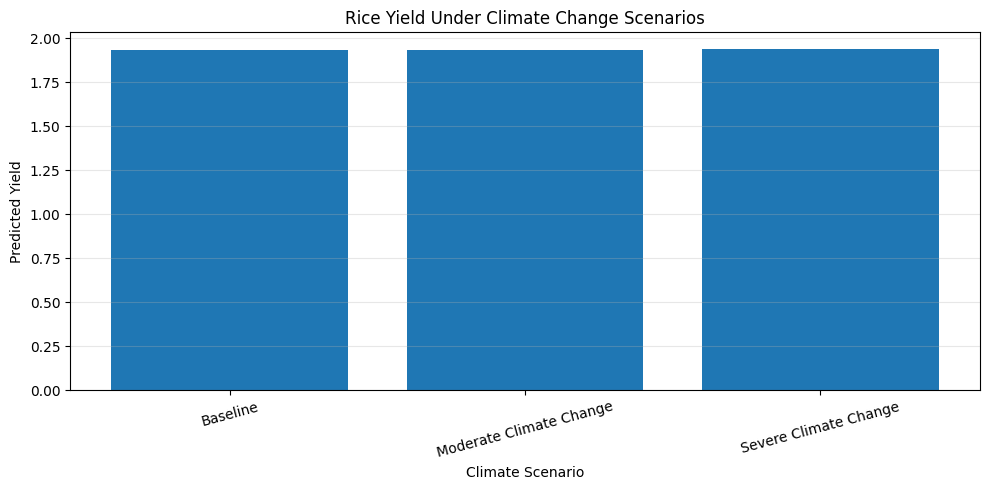

In [ ]:
# Climate scenario comparison

plt.figure(figsize=(10, 5))

plt.bar(
    climate_results.index,
    climate_results["Predicted_Yield"]
)

plt.xlabel("Climate Scenario")
plt.ylabel("Predicted Yield")
plt.title("Rice Yield Under Climate Change Scenarios")
plt.xticks(rotation=15)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# Save Climate Change Scenario Analysis models and results

save_dir = "/content/drive/MyDrive"

# Save climate-focused model
joblib.dump(
    climate_impact_model,
    f"{save_dir}/climate_change_yield_model.pkl"
)

# Save feature names
joblib.dump(
    climate_features,
    f"{save_dir}/climate_change_feature_names.pkl"
)

# Save scenario results
climate_results.to_csv(
    f"{save_dir}/climate_change_scenario_results.csv"
)

# Save model information
climate_model_info = {
    "model": "Random Forest Regressor",
    "crop_analyzed": "Rice",
    "climate_variable": "Annual Rainfall",
    "baseline_rainfall_mm": float(
        climate_results.loc["Baseline", "Annual_Rainfall"]
    ),
    "moderate_rainfall_change": "-10%",
    "severe_rainfall_change": "-25%",
    "MAE": mae_c,
    "RMSE": rmse_c,
    "R2": r2_c,
    "rainfall_feature_importance": 0.036851,
    "limitation": "Model-based rainfall sensitivity analysis; dataset does not contain temperature."
}

joblib.dump(
    climate_model_info,
    f"{save_dir}/climate_change_model_info.pkl"
)

print("Climate Change Scenario Analysis saved successfully!")

print("\nSaved files:")
print("✓ climate_change_yield_model.pkl")
print("✓ climate_change_feature_names.pkl")
print("✓ climate_change_scenario_results.csv")
print("✓ climate_change_model_info.pkl")

Climate Change Scenario Analysis saved successfully!

Saved files:
✓ climate_change_yield_model.pkl
✓ climate_change_feature_names.pkl
✓ climate_change_scenario_results.csv
✓ climate_change_model_info.pkl
